# Bounding boxes in medical images

This example shows how to augment bounding boxes together with their class labels. A bounding box is stored as
`Keypoints` of its 4 corners, so it can be rotated, sheared or even projected. After the augmentation, the new
bounding box is the smallest box around the transformed corners.

The image comes with [scikit-image](https://scikit-image.org): a retinal fundus photograph. The boxes of two
anatomical structures, the optic disc and the macula, are found with a simple image analysis below.

In [1]:
%matplotlib inline
# JPEG keeps the notebook small, since the figures are photos
%config InlineBackend.figure_formats = ['jpeg']
import random

import cv2
import matplotlib.pyplot as plt
import numpy as np
from matplotlib import patches

import solt
import solt.transforms as slt

# SOLT samples the transforms with the `random` module
random.seed(42)
np.random.seed(42)

from scipy import ndimage as ndi
from skimage import color, data, filters, measure, morphology

## Getting the data

In [2]:
img = cv2.resize(data.retina(), (1024, 1024), interpolation=cv2.INTER_AREA)
field_of_view = morphology.erosion(color.rgb2gray(img) > 0.08, morphology.disk(5))

# The optic disc is the brightest region of the blue channel
blue = filters.gaussian(img[..., 2] / 255.0, sigma=11)
disc = measure.label((blue > np.percentile(blue[field_of_view], 99)) & field_of_view)
y0, x0, y1, x1 = max(measure.regionprops(disc), key=lambda r: r.area).bbox
disc_box = (x0, y0, x1 - x0, y1 - y0)

# The macula is the darkest region of the green channel. The border of the field of view is excluded,
# since it has dark camera artefacts. Let's make the box of the macula of the same size as of the disc
green = filters.gaussian(img[..., 1] / 255.0, sigma=18)
green[ndi.distance_transform_edt(field_of_view) < 100] = 1
cy, cx = np.unravel_index(np.argmin(green), green.shape)
size = max(x1 - x0, y1 - y0)
macula_box = (int(cx) - size // 2, int(cy) - size // 2, size, size)

boxes = {'Optic disc': disc_box, 'Macula': macula_box}
boxes

{'Optic disc': (114, 415, 106, 124), 'Macula': (451, 449, 124, 124)}

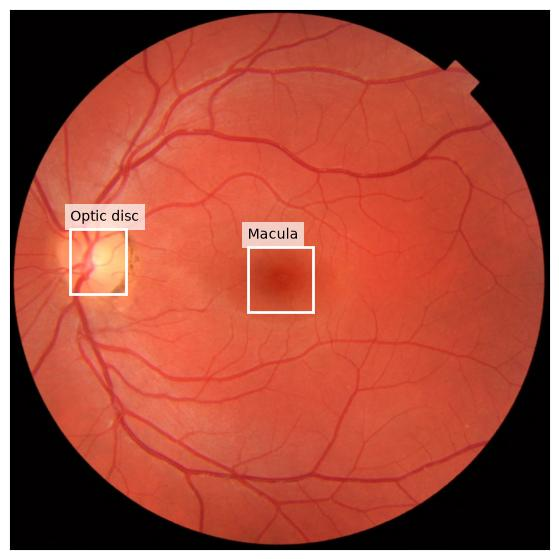

In [3]:
def show_boxes(ax, img, boxes):
    ax.imshow(img)
    for name, (x, y, w, h) in boxes.items():
        ax.add_patch(patches.Rectangle((x, y), w, h, fill=False, color='w', lw=2))
        ax.text(x, y - 15, name, fontsize=10, bbox=dict(facecolor='white', alpha=0.7, lw=0))
    ax.set_xticks([])
    ax.set_yticks([])


fig, ax = plt.subplots(1, 1, figsize=(7, 7))
show_boxes(ax, img, boxes)
plt.show()

## Wrapping the data into `SOLT` format

In [4]:
def box_to_keypoints(box, height, width):
    """Converts a box (x, y, w, h) into the keypoints of its corners."""
    x, y, w, h = box
    corners = np.array([[x, y], [x + w, y], [x + w, y + h], [x, y + h]], dtype=float)
    return solt.Keypoints(corners, height, width)


def keypoints_to_box(kpts, height, width):
    """Returns the smallest box (x, y, w, h) around the keypoints, clipped to the image."""
    pts = kpts.data.copy()
    pts[:, 0] = np.clip(pts[:, 0], 0, width - 1)
    pts[:, 1] = np.clip(pts[:, 1], 0, height - 1)
    x, y = pts.min(axis=0)
    return x, y, pts[:, 0].max() - x, pts[:, 1].max() - y


h, w = img.shape[:2]
disc_kpts = box_to_keypoints(boxes['Optic disc'], h, w)
macula_kpts = box_to_keypoints(boxes['Macula'], h, w)
# Every box is followed by its class label
dc = solt.DataContainer((img, disc_kpts, 0, macula_kpts, 1), 'IPLPL')
class_names = {0: 'Optic disc', 1: 'Macula'}

## Defining a pipeline

In [5]:
stream = solt.Stream([
    slt.Projection(
        solt.Stream([
            slt.Scale(range_x=(0.8, 1.1), p=1),
            slt.Rotate(angle_range=(-90, 90), p=1),
            slt.Shear(range_x=(-0.2, 0.2), range_y=None, p=0.7),
        ]),
        v_range=(1e-6, 3e-4), p=1),
    # Various cropping and padding tricks
    slt.Pad(1000, 'z'),
    slt.Crop(1000, crop_mode='c'),
    slt.Crop(950, crop_mode='r'),
    slt.Pad(1000, 'z'),
    # Intensity augmentations
    slt.GammaCorrection(p=1, gamma_range=(0.5, 3)),
    solt.SelectiveStream([
        solt.SelectiveStream([
            slt.SaltAndPepper(p=1, gain_range=0.01),
            slt.Blur(p=0.5, blur_type='m', k_size=(11,)),
        ]),
        slt.Noise(p=1, gain_range=0.5),
    ]),
])
print(stream.to_yaml())

stream:
  ignore_fast_mode: false
  interpolation: null
  optimize_stack: false
  padding: null
  shuffle: false
  transforms:
  - projection:
      affine_transforms:
        stream:
          ignore_fast_mode: false
          interpolation: null
          optimize_stack: false
          padding: null
          shuffle: false
          transforms:
          - scale:
              ignore_fast_mode: false
              ignore_state: true
              interpolation:
              - bilinear
              - inherit
              p: 1
              padding:
              - z
              - inherit
              range_x:
              - 0.8
              - 1.1
              range_y: null
              same: true
          - rotate:
              angle_range:
              - -90
              - 90
              ignore_fast_mode: false
              ignore_state: true
              interpolation:
              - bilinear
              - inherit
              p: 1
              padding:
    

## Augmentation results

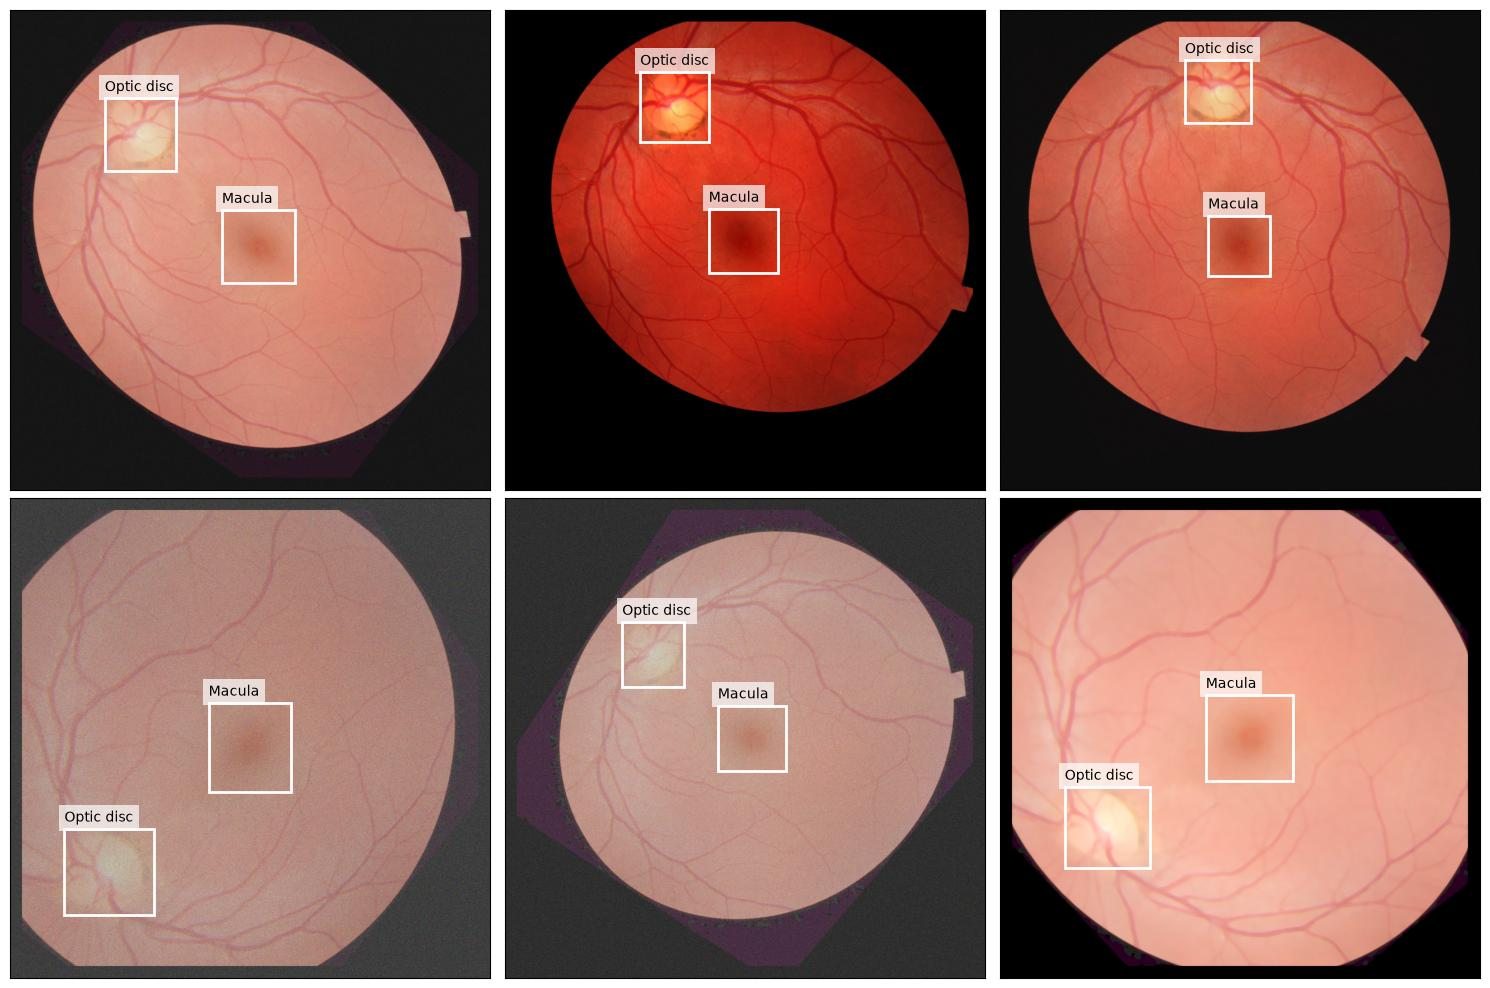

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for ax in axes.ravel():
    img_res, kpts_1, label_1, kpts_2, label_2 = stream(dc, return_torch=False).data
    h_res, w_res = img_res.shape[:2]
    boxes_res = {class_names[label]: keypoints_to_box(kpts, h_res, w_res)
                 for kpts, label in [(kpts_1, label_1), (kpts_2, label_2)]}
    show_boxes(ax, img_res, boxes_res)
plt.tight_layout()
plt.show()